In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt

import polars as pl
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
import torch

from src.dataset.particledataset import RealPulseDataset
from src.model.model import PulseVAE
from src.loss import vae_loss_function, vae_loss_function_log
from src.train import Trainer 

### Датасет

In [3]:
data = pl.read_parquet("datasets/25c25_proccesed.parquet")
data.head(3)

Channel,Timestamp,Board,Energy,EnergyShort,Flags,Probe,Samples,pulse,amplitude,psd,norm_pulse
u16,u64,u16,u16,u16,u32,i32,list[i16],list[f64],f64,f64,list[f64]
0,44313205,0,565,521,16384,1,"[13562, 13566, … 13547]","[-6.733333, -10.733333, … 8.266667]",2290.266667,0.077876,"[-0.00294, -0.004686, … 0.003609]"
0,158492083,0,828,773,16384,1,"[13556, 13554, … 13515]","[-2.266667, -0.266667, … 38.733333]",3264.733333,0.066425,"[-0.000694, -0.000082, … 0.011864]"
0,172405635,0,361,328,16384,1,"[13560, 13543, … 13558]","[-5.3, 11.7, … -3.3]",1381.7,0.091413,"[-0.003836, 0.008468, … -0.002388]"


In [4]:
X = data['norm_pulse']
amplitudes = data['amplitude']

In [5]:
X_train, X_test, amplitudes_train, amplitudes_test = train_test_split(
    X, amplitudes,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

In [6]:
train_dataset = RealPulseDataset(X_train, amplitudes_train)
test_dataset = RealPulseDataset(X_test, amplitudes_test)

In [7]:
train_dataloader = DataLoader(train_dataset, batch_size=256, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=256, shuffle=False)

### Модель

In [38]:
num_epochs = 15
model = PulseVAE(latent_dim=1, out_channels_first=40)
criterion=vae_loss_function_log
optimizer = optim.Adam(model.parameters(), lr=0.001)
sheduler = CosineAnnealingLR(
    optimizer=optimizer,
    T_max=num_epochs,
    eta_min=1e-6
)


In [39]:
history_of_learn = {
    "train_loss_array": [],
    "test_loss_array": []
    }
best_test_loss = float('inf')

In [40]:
trainer = Trainer(
    model=model,
    criterion=criterion,
    optimizer=optimizer,
    device='cuda' if torch.cuda.is_available() else 'cpu',
    train_dataloader=train_dataloader,
    test_dataloader=test_dataloader,
    num_epochs=num_epochs,
    warmup_beta=5,
    max_beta=2e-3, #5e-4
    scheduler=sheduler
)

In [41]:
history_of_learn = trainer.fit()

Epoch -> 1/15


100%|██████████| 399/399 [00:13<00:00, 28.73it/s]


TRAIN loss-> 23.06664444108617
TEST loss -> 18.825550122368604
Epoch -> 2/15


100%|██████████| 399/399 [00:02<00:00, 151.11it/s]


TRAIN loss-> 18.70333372117286
TEST loss -> 17.9540890284947
Epoch -> 3/15


...

TRAIN loss-> 16.27056009456637
TEST loss -> 16.21117491949172
Epoch -> 14/15


100%|██████████| 399/399 [00:03<00:00, 127.42it/s]


TRAIN loss-> 16.256798680743106
TEST loss -> 16.210929239602912
Epoch -> 15/15


100%|██████████| 399/399 [00:03<00:00, 116.71it/s]

TRAIN loss-> 16.24577022631514
TEST loss -> 16.204831266761722


In [42]:
model.load_state_dict(torch.load("checkpoints/best_vae_model.pth", weights_only=True))

<All keys matched successfully>

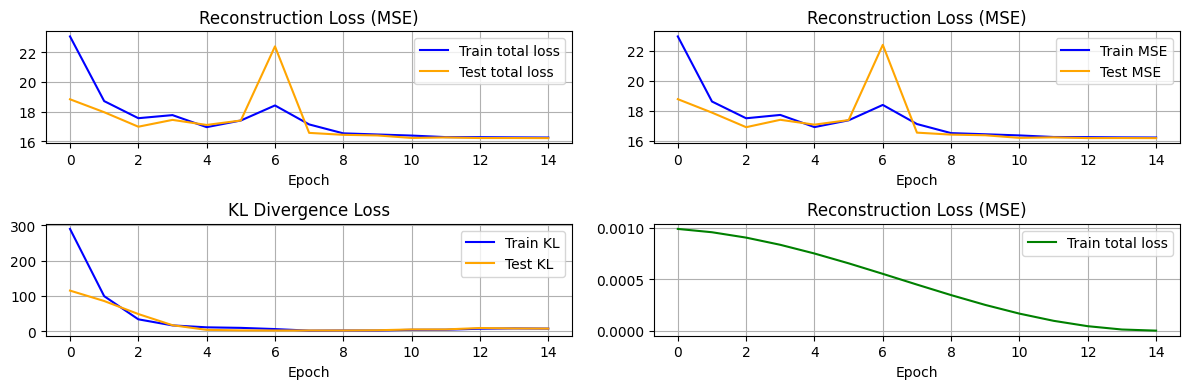

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(2, 2, 1)
plt.plot(history_of_learn['train_loss'], label='Train total loss', color='blue')
plt.plot(history_of_learn['test_loss'], label='Test total loss', color='orange')
plt.title('Reconstruction Loss (MSE)')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)

# 1. Reconstruction Loss (насколько точно восстанавливается форма импульса)
plt.subplot(2, 2, 2)
plt.plot(history_of_learn['train_recon_loss'], label='Train MSE', color='blue')
plt.plot(history_of_learn['test_recon_loss'], label='Test MSE', color='orange')
plt.title('Reconstruction Loss (MSE)')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)

# 2. KL Loss (структурирование латентного пространства)

plt.subplot(2, 2, 3)
plt.plot(history_of_learn['train_kl_loss'], label='Train KL', color='blue')
plt.plot(history_of_learn['test_kl_loss'], label='Test KL', color='orange')
plt.title('KL Divergence Loss')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 4)
plt.plot(history_of_learn['lr'], label='Train total loss', color='green')
plt.title('Reconstruction Loss (MSE)')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)




plt.tight_layout()
plt.show()

In [44]:
model.eval()
with torch.no_grad():
    outputs, mu, logvar = model(torch.tensor(data['norm_pulse'], dtype=torch.float32))

In [45]:
data = data.with_columns(pl.Series("latent_vectors", mu))

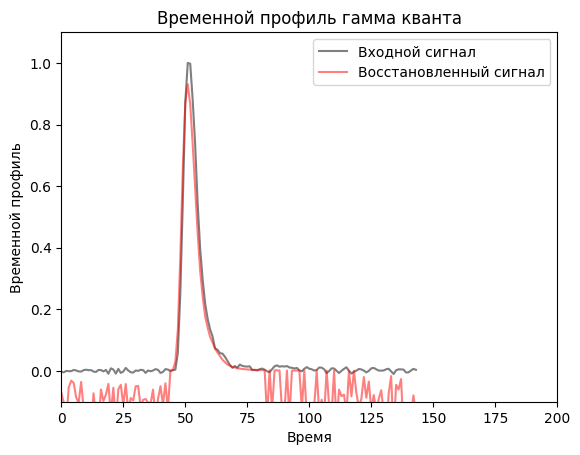

In [46]:
plt.plot(data['norm_pulse'][0], color='black', alpha=0.5, label='Входной сигнал')
plt.plot(outputs.numpy()[0].reshape(-1), color='red', alpha=0.5, label='Восстановленный сигнал')
plt.legend()
plt.title("Временной профиль гамма кванта")
plt.ylabel("Временной профиль")
plt.xlabel("Время")
plt.xlim(0, 200.0)
plt.ylim(-0.1, 1.1)
plt.show()

In [47]:
data.head(1)

Channel,Timestamp,Board,Energy,EnergyShort,Flags,Probe,Samples,pulse,amplitude,psd,norm_pulse,latent_vectors
u16,u64,u16,u16,u16,u32,i32,list[i16],list[f64],f64,f64,list[f64],"array[f32, 1]"
0,44313205,0,565,521,16384,1,"[13562, 13566, … 13547]","[-6.733333, -10.733333, … 8.266667]",2290.266667,0.077876,"[-0.00294, -0.004686, … 0.003609]",[-0.335074]


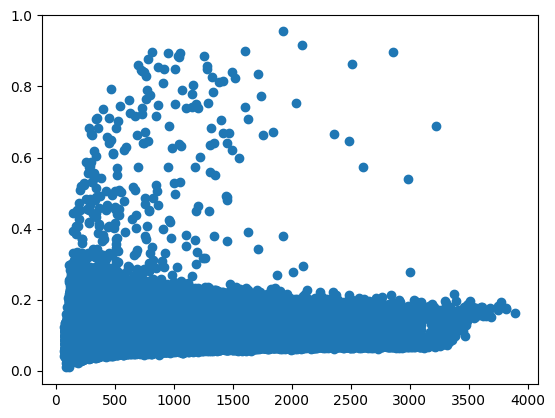

In [48]:
plt.scatter(
    x=data['Energy'],
    y=data['psd']
)

In [49]:
import numpy as np

In [50]:
plt.scatter(
    x=(data['Energy']),
    y=np.array(data['latent_vectors'])[:,1]
)

IndexError: index 1 is out of bounds for axis 1 with size 1

(array([1., 0., 0., ..., 0., 0., 1.], shape=(5000,)),
 array([-0.77407861, -0.7730099 , -0.77194118, ...,  4.56738091,
         4.56844902,  4.56951809], shape=(5001,)),
 <BarContainer object of 5000 artists>)

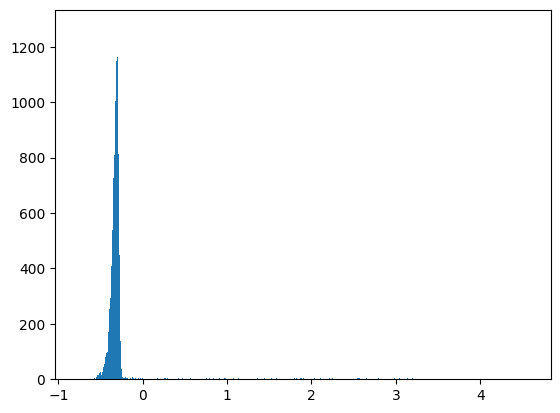

In [52]:
plt.hist(np.array(data['latent_vectors'])[:100000], bins=5000)

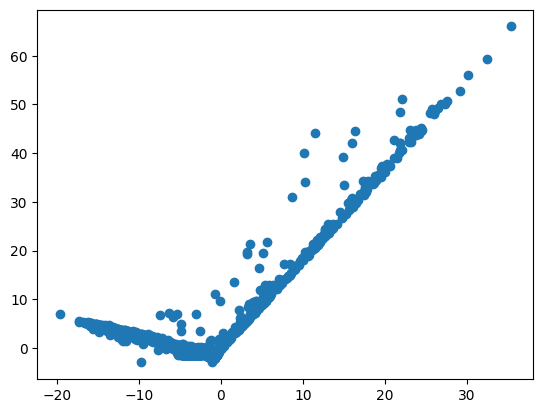

In [ ]:
plt.scatter(
    x=np.array(data['latent_vectors'])[:,1][:10000],
    y=np.array(data['latent_vectors'])[:,0][:10000]
)